# 05 — Gradient boosting

**Input:** `data/processed/features/features.parquet` (notebook 03), and the validation predictions of the two linear models selected in notebook 04.

**Goal:** a model that learns the interactions and the non-linearities the linear models miss. Notebook 04 showed that they **underfit**: a single set of weights cannot describe the climb, the cruise and the approach, and one linear model per flight segment helps, assuming that the phase of flight is known at any time. A tree ensemble can split by itself on the vertical rate, the altitude or the distance, without being told the phase.

**Same structure as part 1 of notebook 04:** candidates tuned on the validation set, compared with the same metrics, the best one selected, regularized and analysed. The selected model is then trained again with the phase of flight as a feature, for a comparison with the same information as the per-segment linear model, and compared with the linear models.

**Evaluation protocol.** Same split by flight, same metrics and same code as notebook 04 (`src/opensky_eta/evaluation.py`): the **MAE** decides, the MAE per segment and the 95th percentile are guardrails, the median is reported, the errors by remaining time are information only, and the paired bootstrap over the flights tells whether a difference is real. The test flights are not used.

## 0. Setup

The constructor of the gradient boosting pipeline (`make_boosting_pipeline`) is in `src/opensky_eta/models.py`, also used by `python -m opensky_eta.train` to retrain the selected model. The early stopping on the validation set, specific to this notebook, is defined below.

In [1]:
import time

import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

from opensky_eta.config import (
    BOOSTING_MODEL_PATH, CATEGORICAL_FEATURES, FEATURES_PATH, FLIGHT_KEY, LABEL,
    LINEAR_PREDICTIONS_PATH, NUMERIC_FEATURES, PHASE_TO_SEGMENT, POINTS_PER_FLIGHT, PROJECT_DIR,
    RANDOM_STATE, SEGMENTS,
)
from opensky_eta.evaluation import (
    REMAINING_BINS_MIN, REMAINING_LABELS, bootstrap_comparison, error_concentration, evaluate,
    flag_suspicious_labels, flight_errors, remaining_time_report, suspicious_label_report,
)
from opensky_eta.models import make_boosting_pipeline
from opensky_eta.plotting import COLORS, set_plot_style

set_plot_style()

MAX_TREES = 3000     # upper bound of the number of trees
BLOCK = 50           # trees added at each step of the early stopping
PATIENCE = 2         # blocks in a row without a real improvement before stopping
MIN_GAIN_MIN = 0.01  # improvement of the validation MAE (min) that counts as real


def fit_with_early_stopping(pipeline, X_train, y_train, X_val, y_val):
    """Fits the pipeline by blocks of BLOCK trees, and stops when the validation MAE has not improved
    by more than MIN_GAIN_MIN during PATIENCE blocks in a row (or at MAX_TREES trees).

    Returns the validation MAE (min) after each block, indexed by the number of trees.
    """
    preprocess, model = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
    X_train_processed = preprocess.fit_transform(X_train)
    X_val_processed = preprocess.transform(X_val)
    history, best, stale = {}, np.inf, 0
    for n_trees in range(BLOCK, MAX_TREES + 1, BLOCK):
        model.set_params(max_iter=n_trees, warm_start=True).fit(X_train_processed, y_train)  # adds BLOCK trees
        history[n_trees] = mean_absolute_error(y_val, model.predict(X_val_processed)) / 60
        if history[n_trees] < best - MIN_GAIN_MIN:
            best, stale = history[n_trees], 0
        else:
            stale += 1
            if stale == PATIENCE:
                break
    return pd.Series(history)


def staged_mae(pipeline, X, y):
    """MAE (min) after each tree of a fitted pipeline: its learning curve."""
    X_processed = pipeline.named_steps["preprocess"].transform(X)
    return np.array([mean_absolute_error(y, prediction) / 60
                     for prediction in pipeline.named_steps["model"].staged_predict(X_processed)])

## 1. Data

Same data as notebook 04: `X` holds the raw features (the trees need no scaling) and `y` the label, in seconds. The test flights are not loaded.

In [2]:
features = pd.read_parquet(FEATURES_PATH)
train = features[features["split"] == "train"]
validation = features[features["split"] == "validation"]

X_train, y_train = train[NUMERIC_FEATURES + CATEGORICAL_FEATURES], train[LABEL]
X_val, y_val = validation[NUMERIC_FEATURES + CATEGORICAL_FEATURES], validation[LABEL]

# Evaluation helpers, as in notebook 04 (phase_of_flight is used to evaluate, never as a feature)
val_segment = validation["phase_of_flight"].map(PHASE_TO_SEGMENT)
val_flight = validation.groupby(FLIGHT_KEY, sort=False).ngroup().to_numpy()

# Validation predictions of the linear reference models (notebook 04), on the same rows
linear = pd.read_parquet(LINEAR_PREDICTIONS_PATH)
assert linear[FLIGHT_KEY + ["time"]].equals(validation[FLIGHT_KEY + ["time"]].reset_index(drop=True)), \
    "the saved predictions must be aligned with the validation rows"
linear_predictions = {name: linear[name].to_numpy() for name in linear.columns.drop(FLIGHT_KEY + ["time"])}

print(f"Train: {len(X_train):,} rows, validation: {len(X_val):,} rows ({val_flight.max() + 1:,} flights), "
      f"{X_train.shape[1]} raw features")
print("Linear references:", ", ".join(linear_predictions))

Train: 1,439,400 rows, validation: 308,460 rows (5,141 flights), 24 raw features
Linear references: Linear, MAE loss, Per segment, MAE loss


## 2. References

The two baselines of notebook 04 and its two selected linear models:
- **constant**: the median remaining time of the training set;
- **naive time to arrival**: remaining distance / current ground speed;
- **linear, MAE loss**: the model selected in part 1 of notebook 04, one set of weights for the whole flight;
- **per segment, MAE loss**: the model selected in part 2 of notebook 04, one linear MAE model per flight segment. Each row is sent to the model of its segment, which assumes that the phase of flight is known at any time (for live flights, from the flight plan for example).

In [3]:
results = {
    "Constant (train median)": evaluate(y_val, np.full(len(y_val), y_train.median()), val_segment),
    "Naive: distance / speed": evaluate(y_val, validation["naive_time_to_arrival_s"], val_segment),
    **{name: evaluate(y_val, prediction, val_segment) for name, prediction in linear_predictions.items()},
}
display(pd.DataFrame(results).T.round(2))

best_linear = min(linear_predictions, key=lambda name: results[name]["MAE (min)"])
print(f"Best linear model: {best_linear}")

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
Constant (train median),44.01,23.52,149.03,78.59,34.22,29.01
Naive: distance / speed,16.06,8.71,42.53,30.68,13.59,6.37
"Linear, MAE loss",8.11,3.03,16.05,14.37,7.26,3.55
"Per segment, MAE loss",7.51,2.62,15.13,14.04,6.53,2.96


Best linear model: Per segment, MAE loss


The bar to beat is the per-segment linear model (MAE 7.5 minutes), which uses the phase of flight. The single linear model (8.1 minutes) is the reference that does not need it.

## 3. The candidate models

### `HistGradientBoostingRegressor`

- **Binning:** each numeric feature is cut into at most 255 intervals (by quantiles) before training.
- **No scaling:** a threshold on a feature does not depend on its unit, so the numeric features are used as they are.
- **Airports as categories:** instead of a one-hot encoding, each airport gets an integer code and the trees split on *groups* of airports directly. As for the linear models, only the airports seen in at least 50 training flights get their own code; the rarer ones share an "infrequent" code (`make_tree_preprocessor` in `src/opensky_eta/preprocessing.py`).

**Two candidates**, which differ only by their loss, as in notebook 04:

| Candidate | Loss | Prediction pulled towards | Hyperparameters to tune |
|---|---|---|---|
| **Gradient boosting, MSE loss** | squared error | the conditional mean | number of trees, size of the trees |
| **Gradient boosting, MAE loss** | absolute error | the conditional median | number of trees, size of the trees |

## 4. Tuning each candidate on the validation set

The hyperparameters of a gradient boosting:
- **the number of trees** $M$: too few, the model underfits; too many, it can start learning the noise of the training flights (overfitting). It is chosen by **early stopping on the validation set**: the trees are added by blocks of 50, the validation MAE is computed after each block, and the training stops when the last 100 trees have improved it by less than 0.01 minute (or at 3,000 trees);
- **the size of the trees** (`max_leaf_nodes`): small trees capture few interactions, large ones can capture complex interactions but fit the training flights more closely;
- **the learning rate** η, fixed at 0.1;
- **the minimum number of rows per leaf** (`min_samples_leaf`), kept at its default value of 20 for the comparison of the losses, then tuned for the selected candidate (section 6).

**Why not the built-in early stopping of scikit-learn.** `HistGradientBoostingRegressor(early_stopping=True)` holds out a random 10 % of the *training rows* to decide when to stop. Since a flight has 60 correlated rows, most held-out rows have neighbours of the same flight in training: the held-out error would be optimistic, and it would stop too late. Our validation set is split **by flight**, so it is used instead. The trees are added to the same model with `warm_start=True` (each `fit` with a larger `max_iter` continues the training instead of starting again).

As for α in notebook 04, the number of trees and the size of the trees are chosen on the validation set, which makes its MAE very slightly optimistic for the selected model; the test set, used once at the end of the project, will give the unbiased error.

number of trees  \
candidate                   max_leaf_nodes                    
Gradient boosting, MSE loss 31                         1100   
                            63                         1150   
                            255                         650   
                            1023                        350   
Gradient boosting, MAE loss 31                         1550   
                            63                         1500   
                            255                         550   
                            1023                        250   

                                            validation MAE (min)  \
candidate                   max_leaf_nodes                         
Gradient boosting, MSE loss 31                              5.68   
                            63                              5.52   
                            255                             5.44   
                            1023                            5.41   
Gradient boosting, MAE loss 31                              5.21   
                            63                              5.15   
                            255                             5.17   
                            1023                            5.25   

                                            training time (min)  
candidate                   max_leaf_nodes                       
Gradient boosting, MSE loss 31                             2.78  
                            63                             3.24  
                            255                            3.14  
                            1023                           2.61  
Gradient boosting, MAE loss 31                             6.91  
                            63                             8.08  
                            255                            3.48  
                            1023                           2.38

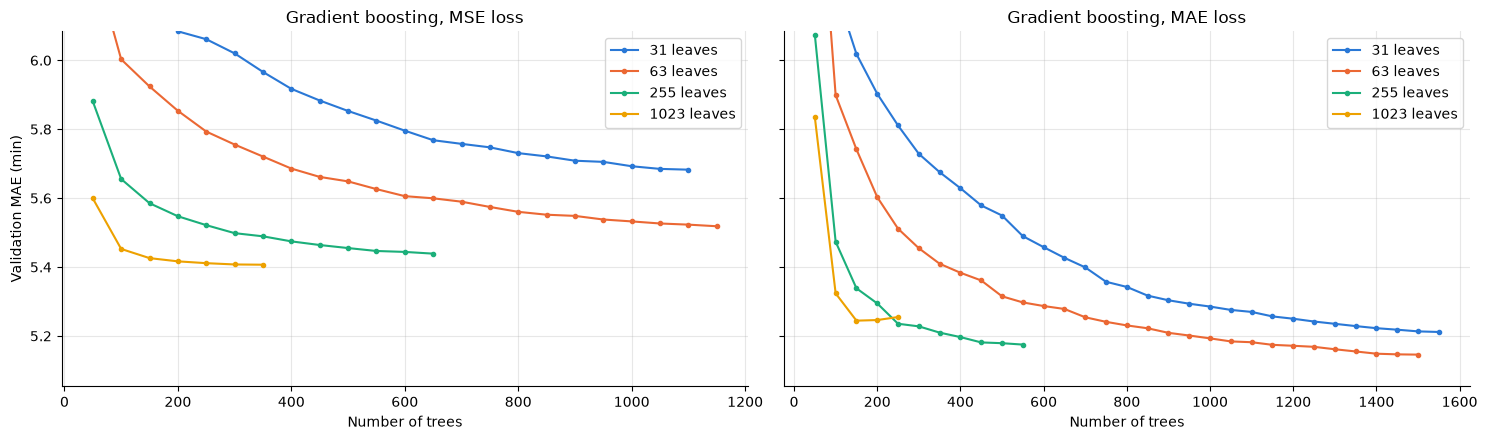

Gradient boosting, MSE loss: 1023 leaves, 350 trees
Gradient boosting, MAE loss: 63 leaves, 1500 trees


In [4]:
LOSSES = {"Gradient boosting, MSE loss": "squared_error", "Gradient boosting, MAE loss": "absolute_error"}
LEAF_GRID = [31, 63, 255, 1023]

rows, curves, tuned_models, best_mae = [], {}, {}, {}
for name, loss in LOSSES.items():
    for leaves in LEAF_GRID:
        start = time.time()
        model = make_boosting_pipeline(loss, leaves)
        curve = fit_with_early_stopping(model, X_train, y_train, X_val, y_val)
        curves[(name, leaves)] = curve
        rows.append({"candidate": name, "max_leaf_nodes": leaves, "number of trees": curve.index[-1],
                     "validation MAE (min)": curve.iloc[-1],
                     "training time (min)": (time.time() - start) / 60})
        if curve.iloc[-1] < best_mae.get(name, np.inf):  # only the best model of each candidate is kept
            best_mae[name], tuned_models[name] = curve.iloc[-1], model
tuning = pd.DataFrame(rows).set_index(["candidate", "max_leaf_nodes"])
display(tuning.round(2))

fig, axes = plt.subplots(1, len(LOSSES), figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, LOSSES):
    for leaves in LEAF_GRID:
        curve = curves[(name, leaves)]
        ax.plot(curve.index, curve.values, marker=".", label=f"{leaves} leaves")
    ax.set_xlabel("Number of trees")
    ax.set_title(name)
    ax.legend()
axes[0].set_ylabel("Validation MAE (min)")
axes[0].set_ylim(top=max(curve.iloc[min(3, len(curve) - 1)] for curve in curves.values()))  # zoom: from 200 trees on
plt.tight_layout()
plt.show()

best_params = {name: tuning.loc[name, "validation MAE (min)"].idxmin() for name in LOSSES}
for name, model in tuned_models.items():
    assert model.named_steps["model"].max_leaf_nodes == best_params[name]
    print(f"{name}: {best_params[name]} leaves, {model.named_steps['model'].n_iter_} trees")

- **With the MAE loss, the size of the trees barely matters, as long as the number of trees adapts:** the four sizes end within 0.1 minute of each other (5.21, 5.15, 5.17 and 5.25 minutes for 31, 63, 255 and 1,023 leaves). The best size, 63 leaves, is surrounded by worse ones on both sides: the optimum is inside the grid. Small trees need many more of them: about 1,500 trees with 31 or 63 leaves, 250 with 1,023 leaves.
- **Large trees learn fast, then start to overfit:** with 1,023 leaves, the validation MAE goes slightly up again after ~150 trees, and the early stopping catches it. With 63 leaves, it is still decreasing very slowly when the training stops (less than 0.01 minute per 100 trees): more trees would only gain a few hundredths of a minute.
- **With the MSE loss, larger trees are better** (from 5.68 minutes with 31 leaves to 5.41 minutes with 1,023 leaves, the largest size tried), but the gain flattens (5.44 → 5.41 from 255 to 1,023 leaves), and this candidate stays clearly behind the MAE loss.

## 5. Comparison of the tuned candidates and selection

The best model of each candidate comes directly from the tuning: the early stopping left it with its chosen number of trees, so nothing has to be trained again. Same decision rule as in notebook 04: the **MAE** decides, the guardrails are checked, and the paired bootstrap tells whether the differences with the best candidate are larger than the noise.

In [5]:
tuned_predictions = {name: model.predict(X_val) for name, model in tuned_models.items()}
for name, prediction in tuned_predictions.items():
    results[name] = evaluate(y_val, prediction, val_segment)
display(pd.DataFrame(results).T.round(2))

best_candidate = min(tuned_predictions, key=lambda name: results[name]["MAE (min)"])
boosting_model, boosting_pred = tuned_models[best_candidate], tuned_predictions[best_candidate]
print(f"Lowest validation MAE: {best_candidate}")
print("Paired bootstrap against this candidate (a positive difference means a worse MAE):")
display(bootstrap_comparison(y_val, tuned_predictions, val_flight, reference=best_candidate))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
Constant (train median),44.01,23.52,149.03,78.59,34.22,29.01
Naive: distance / speed,16.06,8.71,42.53,30.68,13.59,6.37
"Linear, MAE loss",8.11,3.03,16.05,14.37,7.26,3.55
"Per segment, MAE loss",7.51,2.62,15.13,14.04,6.53,2.96
"Gradient boosting, MSE loss",5.41,2.03,13.62,9.24,5.07,2.24
"Gradient boosting, MAE loss",5.15,1.89,11.80,8.84,4.84,2.08


Lowest validation MAE: Gradient boosting, MAE loss
Paired bootstrap against this candidate (a positive difference means a worse MAE):


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
"Gradient boosting, MSE loss",5.41,"[4.99, 5.88]",0.26,"[+0.13, +0.39]"
"Gradient boosting, MAE loss",5.15,"[4.73, 5.61]",0.0,"[+0.00, +0.00]"


**Decision: gradient boosting with the MAE loss is selected** (63 leaves, 1,500 trees).
- **Decision metric:** the lowest MAE, 5.15 minutes. The MSE loss is +0.26 minute behind, with an interval of about [+0.13, +0.39]: the difference is real.
- **Guardrails:** they all agree: a lower median (1.9 vs 2.0 minutes), a lower 95th percentile (11.8 vs 13.6 minutes), and a lower MAE in every segment.
- **Same conclusion as for the linear models, with a much smaller gap** (0.26 minute here, 3.6 minutes between the Ridge and the linear MAE model). Trees are less sensitive to the extreme labels: the value of a leaf only sets the prediction of the rows of that leaf, so an impossible label pulls a few predictions, not all of them.

## 6. Regularization of the selected model: a minimum number of flights per leaf

`min_samples_leaf` is the minimum number of training rows in a leaf. Its default value, 20 rows, is meant for independent rows. Ours are not: a flight has 60 rows that look alike (same route, neighbouring positions), so a leaf of 20 rows can contain **a single flight**. Its value (the median of the residuals of its rows, for the MAE loss) then describes that flight, not a behaviour shared by several flights. This is the same trap as the threshold of the frequent airports in notebook 04: a threshold in rows does not mean what we think when the rows are grouped by flight.

The minimum is therefore expressed **in flights**: 1, 5 or 20 flights per leaf, i.e. 60, 300 or 1,200 rows. The selected candidate (same loss, same size of the trees) is trained again for each value, with the same early stopping, and compared with the default value.

In [6]:
MIN_FLIGHTS_PER_LEAF = [1, 5, 20]

leaf_models = {"default (20 rows)": boosting_model}
for n_flights in MIN_FLIGHTS_PER_LEAF:
    model = make_boosting_pipeline(LOSSES[best_candidate], best_params[best_candidate],
                                   min_samples_leaf=n_flights * POINTS_PER_FLIGHT)
    fit_with_early_stopping(model, X_train, y_train, X_val, y_val)
    leaf_models[f"{n_flights} flight{'s' if n_flights > 1 else ''} ({n_flights * POINTS_PER_FLIGHT} rows)"] = model

leaf_predictions = {name: model.predict(X_val) for name, model in leaf_models.items()}
leaf_results = pd.DataFrame.from_dict({
    name: {"min_samples_leaf": model.named_steps["model"].min_samples_leaf,
           "number of trees": model.named_steps["model"].n_iter_,
           "train MAE (min)": mean_absolute_error(y_train, model.predict(X_train)) / 60,
           **evaluate(y_val, leaf_predictions[name], val_segment)}
    for name, model in leaf_models.items()
}, orient="index").rename_axis("minimum per leaf")
display(leaf_results.round(2))

best_leaf_setting = leaf_results["MAE (min)"].idxmin()
print(f"Lowest validation MAE: {best_leaf_setting}")
print("Paired bootstrap against this setting (a positive difference means a worse MAE):")
display(bootstrap_comparison(y_val, leaf_predictions, val_flight, reference=best_leaf_setting))

# The final model: the selected candidate with its best minimum per leaf
boosting_model, boosting_pred = leaf_models[best_leaf_setting], leaf_predictions[best_leaf_setting]
best_min_samples_leaf = boosting_model.named_steps["model"].min_samples_leaf
results[best_candidate] = evaluate(y_val, boosting_pred, val_segment)

,min_samples_leaf,number of trees,train MAE (min),MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
minimum per leaf,,,,,,,,,
default (20 rows),20,1500,3.27,5.15,1.89,11.80,8.84,4.84,2.08
1 flight (60 rows),60,850,3.69,5.20,1.91,12.03,9.06,4.84,2.08
5 flights (300 rows),300,1050,3.78,5.21,1.91,11.92,9.07,4.85,2.10
20 flights (1200 rows),1200,1200,4.18,5.39,1.91,12.00,9.32,5.02,2.19


Lowest validation MAE: default (20 rows)
Paired bootstrap against this setting (a positive difference means a worse MAE):


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
default (20 rows),5.15,"[4.73, 5.61]",0.0,"[+0.00, +0.00]"
1 flight (60 rows),5.2,"[4.79, 5.67]",0.06,"[+0.02, +0.10]"
5 flights (300 rows),5.21,"[4.80, 5.69]",0.07,"[-0.01, +0.15]"
20 flights (1200 rows),5.39,"[4.92, 5.91]",0.24,"[+0.10, +0.42]"


- **The default value (20 rows per leaf) stays the best.** A larger minimum, expressed in flights, does reduce the gap between the training and validation errors (training MAE from 3.3 to 3.7 minutes with 1 flight per leaf, 4.2 minutes with 20 flights), but the validation error does not improve.
- **The guardrails agree:** the default value has the lowest 95th percentile and the lowest MAE before the cruise; the other segments are equal with 1 or 5 flights per leaf, and worse with 20 flights.
- **So the gap between the training and validation errors is not harmful overfitting.** The small leaves do describe a few flights, but what they learn is partly useful on new flights too (probably because the same routes, airports and procedures come back), and forcing larger leaves removes more signal than noise. The regularized models also stop earlier (850 to 1,200 trees instead of 1,500).
- **The selected model is unchanged:** MAE loss, 63 leaves, 20 rows per leaf, 1,500 trees. The analyses below are those of the candidate selected in section 5.

## 7. Analysis of the selected model

From now on, the analyses focus on the selected model (the default minimum of 20 rows per leaf, see section 6).

### 7.1 What the model uses: permutation importance

The **permutation importance** measures how much the model relies on a feature: the values of the feature are shuffled across the validation rows, and the increase of the validation MAE is measured. A large increase means that the model needs this feature.

The features are permuted **by group**: several features carry the same information (the distance and the naive time, the three altitudes, the coordinates of the aircraft and of the airports). Permuting one of them alone would underestimate its importance, since the model can still read the information in its neighbours.

,MAE increase (min),spread over the repeats (min)
distance and naive time to arrival,55.12,0.05
speed and vertical rate,5.26,0.05
heading,4.36,0.08
progress along the route,3.69,0.01
airport codes,2.03,0.04
altitude,1.27,0.01
"coordinates (aircraft, airports)",1.21,0.01
time of day,0.38,0.01


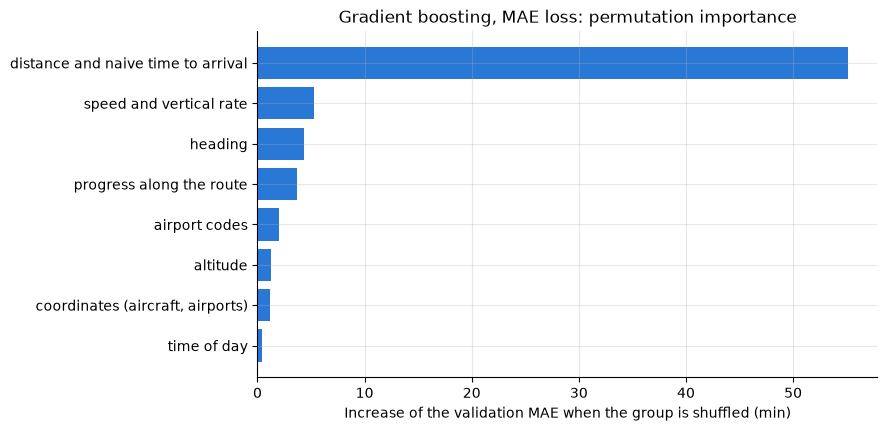

In [7]:
FEATURE_GROUPS = {
    "distance and naive time to arrival": ["distance_to_arrival_km", "naive_time_to_arrival_s"],
    "progress along the route": ["distance_from_departure_km", "route_length_km", "route_progress"],
    "heading": ["heading_error_cos", "heading_error_sin", "heading_sin", "heading_cos"],
    "time of day": ["hour_sin", "hour_cos"],
    "altitude": ["altitude_ft", "geo_altitude_ft", "height_above_arrival_ft"],
    "speed and vertical rate": ["speed_kt", "vertical_rate_ft_min"],
    "coordinates (aircraft, airports)": ["lat", "lon", "departure_lat", "departure_lon", "arrival_lat", "arrival_lon"],
    "airport codes": CATEGORICAL_FEATURES,
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(NUMERIC_FEATURES + CATEGORICAL_FEATURES)

N_REPEATS = 3
rng = np.random.default_rng(RANDOM_STATE)
reference_mae = mean_absolute_error(y_val, boosting_pred) / 60
importance = {}
for group, columns in FEATURE_GROUPS.items():
    increases = []
    for _ in range(N_REPEATS):
        permuted = X_val.copy()
        permuted[columns] = X_val[columns].to_numpy()[rng.permutation(len(X_val))]
        increases.append(mean_absolute_error(y_val, boosting_model.predict(permuted)) / 60 - reference_mae)
    importance[group] = {"MAE increase (min)": np.mean(increases), "spread over the repeats (min)": np.ptp(increases)}
importance = pd.DataFrame(importance).T.sort_values("MAE increase (min)")
display(importance[::-1].round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance["MAE increase (min)"])
ax.set_xlabel("Increase of the validation MAE when the group is shuffled (min)")
ax.set_title(f"{best_candidate}: permutation importance")
plt.show()

- **The distance and the naive time to arrival carry almost everything:** shuffling them multiplies the error by more than ten (+55 minutes). As for the linear models, the model starts from "remaining distance / speed".
- **Then come the speed and the vertical rate (+5.3 minutes), the heading (+4.4) and the progress along the route (+3.7).** These groups describe the phase of flight and the approach (climbing or descending, flying towards the destination or not, beginning or end of the route): this is the information that the linear models of notebook 04 needed in the form of separate segment models. The trees use it by themselves.
- **The airport codes (+2.0), the altitude (+1.3) and the coordinates (+1.2) bring less, and the time of day almost nothing (+0.4).** These groups overlap (an airport code and its coordinates say the same thing), so each importance is a lower bound of the information of the group: the model can partly read it elsewhere.
- The three repetitions differ by less than 0.1 minute: these importances are stable.

### 7.2 Is the model overfitting?

Same two checks as in notebook 04:
1. the training and validation errors of the selected model;
2. the errors along the training, tree after tree, up to the number of trees chosen by the early stopping (the training error on a sample of 300,000 training rows, to keep it fast).

Train MAE: 3.27 min, validation MAE: 5.15 min (1500 trees)


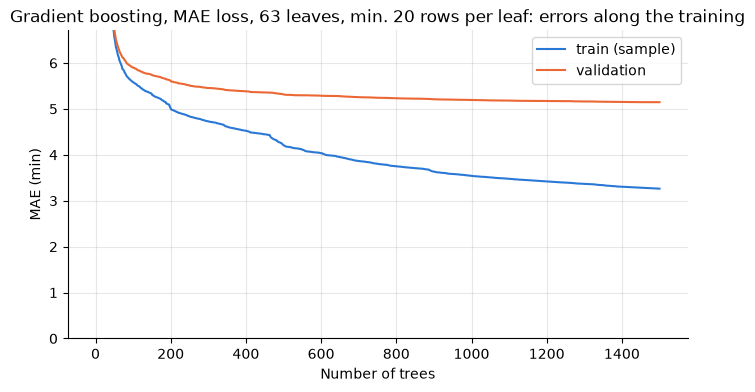

In [8]:
best_leaves = best_params[best_candidate]
n_trees = boosting_model.named_steps["model"].n_iter_
train_sample = X_train.sample(300_000, random_state=RANDOM_STATE)
train_curve = staged_mae(boosting_model, train_sample, y_train.loc[train_sample.index])
val_curve = staged_mae(boosting_model, X_val, y_val)

print(f"Train MAE: {mean_absolute_error(y_train, boosting_model.predict(X_train)) / 60:.2f} min, "
      f"validation MAE: {mean_absolute_error(y_val, boosting_pred) / 60:.2f} min ({n_trees} trees)")

fig, ax = plt.subplots(figsize=(8, 4))
trees = np.arange(1, n_trees + 1)
ax.plot(trees, train_curve, label="train (sample)")
ax.plot(trees, val_curve, label="validation")
ax.set_xlabel("Number of trees")
ax.set_ylabel("MAE (min)")
ax.set_ylim(0, max(train_curve[49], val_curve[49]))  # zoom: from the 50th tree on
ax.set_title(f"{best_candidate}, {best_leaves} leaves, min. {best_min_samples_leaf} rows per leaf: errors along the training")
ax.legend()
plt.show()

- **This time, the training error is clearly lower than the validation error** (3.3 vs 5.15 minutes): unlike the linear models, the trees are flexible enough to learn part of the training flights themselves. With 60 correlated rows per flight and at least 20 rows per leaf, a leaf can describe a single flight.
- **But the validation error keeps decreasing along the training and never goes up:** the extra flexibility is still useful on new flights, so this gap is not harmful overfitting. Section 6 confirmed it: forcing larger leaves (1 to 20 flights per leaf) reduces the gap, but does not improve the validation error.

### 7.3 Where does the model fail?

Error of the selected model by flight segment and, for information, by remaining time, next to the best linear model and the naive baseline.

,Naive: distance / speed,"Per segment, MAE loss","Gradient boosting, MAE loss"
pre,30.68,14.04,8.84
cruise,13.59,6.53,4.84
post,6.37,2.96,2.08


MAE by remaining time (min), information only


,share of rows (%),Naive: distance / speed,"Per segment, MAE loss","Gradient boosting, MAE loss"
< 15 min,14.9,4.3,2.8,1.6
15-30 min,19.3,8.4,3.6,2.3
30-60 min,31.3,10.9,3.8,2.9
1-2 h,22.0,14.8,4.7,3.7
2-4 h,9.1,31.3,11.9,10.0
4-8 h,2.5,91.2,58.6,33.1
> 8 h,1.0,193.3,159.0,97.4


Relative error (%) = MAE / mean true remaining time of the group, information only


,Naive: distance / speed,"Per segment, MAE loss","Gradient boosting, MAE loss"
< 15 min,58.3,38.3,22.1
15-30 min,36.8,15.7,10.2
30-60 min,25.4,8.9,6.7
1-2 h,17.6,5.5,4.4
2-4 h,19.8,7.5,6.3
4-8 h,27.3,17.5,9.9
> 8 h,31.5,25.9,15.9


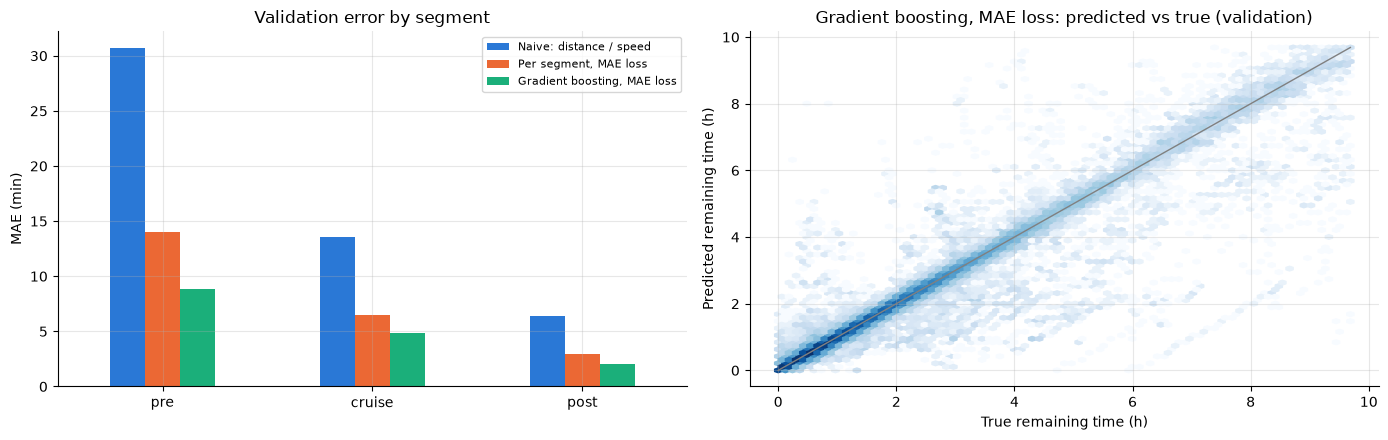

In [9]:
compared = {
    "Naive: distance / speed": validation["naive_time_to_arrival_s"].to_numpy(),
    best_linear: linear_predictions[best_linear],
    best_candidate: boosting_pred,
}
by_segment = pd.DataFrame({name: evaluate(y_val, pred, val_segment) for name, pred in compared.items()})
by_segment = by_segment.loc[[f"MAE {segment} (min)" for segment in SEGMENTS]]
by_segment.index = SEGMENTS
display(by_segment.round(2))

mae_table, relative_table = remaining_time_report(y_val, compared)
print("MAE by remaining time (min), information only")
display(mae_table.round(1))
print("Relative error (%) = MAE / mean true remaining time of the group, information only")
display(relative_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_segment.plot.bar(ax=axes[0], rot=0)
axes[0].set_ylabel("MAE (min)")
axes[0].set_title("Validation error by segment")
axes[0].legend(fontsize=8)
limit = np.percentile(y_val / 3600, 99.5)
axes[1].hexbin(y_val / 3600, boosting_pred / 3600, gridsize=80, bins="log", cmap="Blues", mincnt=1,
               extent=(0, limit, 0, limit))
axes[1].plot([0, limit], [0, limit], color="gray", linewidth=1)
axes[1].set_xlabel("True remaining time (h)")
axes[1].set_ylabel("Predicted remaining time (h)")
axes[1].set_title(f"{best_candidate}: predicted vs true (validation)")
plt.tight_layout()
plt.show()

- **Every segment improves compared with the best linear model** (one model per segment): by about a third before the cruise (14.0 → 8.8 minutes) and after the cruise (3.0 → 2.1), by a quarter in the cruise (6.5 → 4.8). The climb remains the hardest part.
- **The trees do better than the linear models in every segment, without being told the phase:** the segment-specific behaviour that the linear models only get through three separate models, the trees learn it from the speed, the vertical rate, the heading and the distance.
- **By remaining time** (information only), the gain is everywhere: 1.6 minutes in the last 15 minutes (2.8 for the linear model), and the relative error beyond 4 hours goes from 17-26 % to 10-16 %. The long flights remain the largest errors in minutes.
- On the scatter plot, most points lie on the diagonal. The far-off points are a small minority; many of them are predictions much shorter than the label, far from the arrival: the impossible labels studied in section 7.4.

### 7.4 The worst-predicted flights

Same analysis as for the linear models in notebook 04 (sections 6.5 and 11), for the selected model and next to the two linear models. The errors are summed up **by flight**: if OpenSky merged two flights of the same aircraft into one record, or estimated a wrong arrival airport, all the points of the flight get an impossible label. Three questions: are the errors concentrated on a few flights? What do these flights look like? Is their label plausible?

**Checking a label.** The remaining time at the first sampled point (just after the take-off) is close to the duration of the flight, so *route length / this time* is the **average speed implied by the label**. It is compared with the typical speed of the flights of the same route length (median over the training flights, by deciles of route length: from ~250 kt on short routes to ~450 kt on long-haul routes, see notebook 04, section 6.5). A label is flagged as **suspicious** when:
- the departure and arrival airports are the same (a return to the departure airport, a local flight): the distance to the arrival does not describe the flight;
- the implied speed is below 0.6 times the typical speed: the label is far too long (for example several flights merged into one record, the ground time of the stopover included);
- the implied speed is above 1.6 times the typical speed: the label is far too short (for example a wrong arrival airport).

The two thresholds flag about 2 % and 0.7 % of the training flights (notebook 04, section 6.5): only flights far from normal are flagged. The functions are in `src/opensky_eta/evaluation.py`.

Share of the total error made on the worst flights:


,worst 1% of the flights,worst 5% of the flights,worst 10% of the flights
"Linear, MAE loss",0.264,0.521,0.597
"Per segment, MAE loss",0.280,0.527,0.602
"Gradient boosting, MAE loss",0.272,0.480,0.564


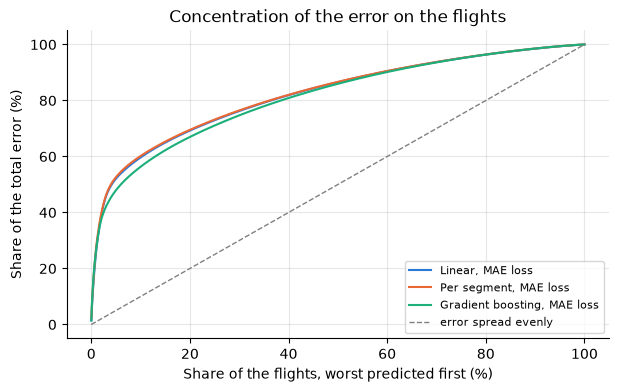

Flights shared with the 50 worst flights of the gradient boosting: Linear, MAE loss 29 of 50, Per segment, MAE loss 29 of 50
The 15 worst-predicted validation flights of the Gradient boosting, MAE loss:


,,,departure,arrival,route_length_km,duration (h),implied_speed_kt,speed / typical speed,suspicious label,"Gradient boosting, MAE loss: MAE (min)","Gradient boosting, MAE loss: mean signed error (min)"
icao24,firstSeen,lastSeen,,,,,,,,,
8a06f0,1.772335e+09,1772397955,WMKK,YPPH,4140.16,17.56,127.33,0.28,True,365.26,-364.29
76cccb,1.772331e+09,1772401375,YMML,VHHH,7412.32,19.56,204.63,0.45,True,353.45,-350.57
4b9e05,1.772370e+09,1772401274,EDDF,LTFJ,1900.51,8.56,119.84,0.31,True,314.41,-314.41
89909f,1.772361e+09,1772376943,RCTP,RCTP,0.00,4.33,0.00,0.00,True,261.46,258.79
7c77f9,1.772352e+09,1772398880,YMML,YSSY,705.61,12.92,29.49,0.08,True,241.94,-240.15
76cd03,1.772286e+09,1772376228,YBBN,WSAP,6150.98,13.63,243.65,0.54,True,232.14,-228.90
a2f5b8,1.772356e+09,1772398519,KCVG,67KY,28.61,11.83,1.31,0.01,True,207.39,-206.89
400683,1.772357e+09,1772406147,EGLL,MBPV,6884.64,13.62,273.02,0.61,False,204.04,-187.37
3c56f3,1.772366e+09,1772403141,EDDB,EDDS,508.00,10.34,26.53,0.09,True,174.50,-174.44


Suspicious labels:


,flights,share of the flights,"Linear, MAE loss: share of its worst 1 %","Linear, MAE loss: share of its total error","Per segment, MAE loss: share of its worst 1 %","Per segment, MAE loss: share of its total error","Gradient boosting, MAE loss: share of its worst 1 %","Gradient boosting, MAE loss: share of its total error"
same departure and arrival airport,76.0,0.015,0.385,0.160,0.385,0.159,0.212,0.108
implied speed < 0.6 x typical,84.0,0.016,0.423,0.199,0.423,0.197,0.596,0.231
implied speed > 1.6 x typical,46.0,0.009,0.115,0.043,0.115,0.056,0.019,0.018
suspicious label,206.0,0.040,0.923,0.402,0.923,0.412,0.827,0.357


,"MAE, all the flights (min)",MAE without the suspicious labels (min)
information only,,
"Linear, MAE loss",8.11,5.06
"Per segment, MAE loss",7.51,4.61
"Gradient boosting, MAE loss",5.15,3.45


In [10]:
train_flights = flight_errors(train)
val_flights = flight_errors(validation, {**linear_predictions, best_candidate: boosting_pred})
flags, speed_ratio = flag_suspicious_labels(val_flights, train_flights)
flight_mae = {name: val_flights[f"{name}: MAE (min)"] for name in [*linear_predictions, best_candidate]}

print("Share of the total error made on the worst flights:")
display(pd.DataFrame({name: error_concentration(mae)[0] for name, mae in flight_mae.items()}).T.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for name, mae in flight_mae.items():
    curve = error_concentration(mae)[1]
    ax.plot(np.arange(1, len(curve) + 1) / len(curve) * 100, curve * 100, label=name)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="error spread evenly")
ax.set_xlabel("Share of the flights, worst predicted first (%)")
ax.set_ylabel("Share of the total error (%)")
ax.set_title("Concentration of the error on the flights")
ax.legend(fontsize=8)
plt.show()

worst_50 = {name: set(mae.nlargest(50).index) for name, mae in flight_mae.items()}
print("Flights shared with the 50 worst flights of the gradient boosting: " + ", ".join(
    f"{name} {len(worst_50[name] & worst_50[best_candidate])} of 50" for name in linear_predictions))

print(f"The 15 worst-predicted validation flights of the {best_candidate}:")
worst = (val_flights.assign(**{"speed / typical speed": speed_ratio, "suspicious label": flags["suspicious label"]})
         .nlargest(15, f"{best_candidate}: MAE (min)"))
columns = ["departure", "arrival", "route_length_km", "first_remaining_h", "implied_speed_kt", "speed / typical speed",
           "suspicious label", f"{best_candidate}: MAE (min)", f"{best_candidate}: mean signed error (min)"]
display(worst[columns].rename(columns={"first_remaining_h": "duration (h)"}).round(2))

print("Suspicious labels:")
display(suspicious_label_report(flags, flight_mae).round(3))
display(pd.DataFrame({
    name: {"MAE, all the flights (min)": mae.mean(),
           "MAE without the suspicious labels (min)": mae[~flags["suspicious label"]].mean()}
    for name, mae in flight_mae.items()
}).T.round(2).rename_axis("information only"))

- **The error of the gradient boosting is a little less concentrated than that of the linear models, but still very much:** its 1 % worst flights make 27 % of its error, its 5 % worst 48 % (52 to 53 % for the linear models).
- **Its worst flights are largely the same as those of the linear models** (29 of its 50 worst flights are also among the 50 worst of each linear model), and **11 of its 15 worst flights have a suspicious label:** Kuala Lumpur → Perth in 17.6 hours, Taipei → Taipei, Frankfurt → Istanbul in 8.6 hours… The 4 others (London → Providenciales, Osaka → Perth, São Paulo → Miami, Tokyo → Sydney) are long-haul flights whose implied speed is 0.60 to 0.69 times the typical speed: just above the threshold, and very likely the same problem (labels several hours too long). For almost all of them, the model predicts a normal flight, much shorter than the label (large negative signed errors); Taipei → Taipei is the exception, where it predicts more time than the label.
- **The suspicious labels make 36 % of its total error**, and 83 % of its 1 % worst flights. Without them, its MAE would be 3.45 minutes instead of 5.15 (information only).
- **The gain over the linear models is not an effect of these flights:** without the suspicious labels, the gradient boosting still reduces the error of the per-segment linear model by a quarter (4.61 → 3.45 minutes).
- **The trees suffer less from some impossible labels than the linear models:** the flights with the same departure and arrival airport make 11 % of their error (16 % for the linear models), the labels far too short 2 % (4 to 6 %). The labels far too long remain: no model can predict that a flight will be followed by another one in the same record.

## 8. The same information as the per-segment linear model: the phase of flight as a feature

The per-segment linear model of notebook 04 uses the phase of flight (assumed to be known at any time), while the gradient boosting above does not: the comparison is not made with the same information. For a fair comparison, the selected model is trained again with the segment of each row (`pre`, `cruise`, `post`, from `phase_of_flight`) as an extra categorical feature, under the same assumption. It keeps the loss, the size of the trees and the minimum per leaf of the selected model; the number of trees is chosen again by the early stopping.

In [11]:
X_train_phase = X_train.assign(segment=train["phase_of_flight"].map(PHASE_TO_SEGMENT))
X_val_phase = X_val.assign(segment=val_segment)

start = time.time()
phase_model = make_boosting_pipeline(LOSSES[best_candidate], best_params[best_candidate],
                                     min_samples_leaf=best_min_samples_leaf,
                                     categorical_features=CATEGORICAL_FEATURES + ["segment"])
phase_curve = fit_with_early_stopping(phase_model, X_train_phase, y_train, X_val_phase, y_val)
phase_pred = phase_model.predict(X_val_phase)
phase_name = f"{best_candidate}, with the phase"
results[phase_name] = evaluate(y_val, phase_pred, val_segment)
print(f"{phase_name}: {phase_model.named_steps['model'].n_iter_} trees, "
      f"trained in {(time.time() - start) / 60:.1f} min")

display(pd.DataFrame({name: results[name] for name in [best_linear, best_candidate, phase_name]}).T.round(2))
print("Paired bootstrap against the gradient boosting without the phase (a negative difference means a better MAE):")
display(bootstrap_comparison(y_val, {best_candidate: boosting_pred, phase_name: phase_pred}, val_flight,
                             reference=best_candidate))

Gradient boosting, MAE loss, with the phase: 850 trees, trained in 4.1 min


,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
"Per segment, MAE loss",7.51,2.62,15.13,14.04,6.53,2.96
"Gradient boosting, MAE loss",5.15,1.89,11.80,8.84,4.84,2.08
"Gradient boosting, MAE loss, with the phase",5.22,1.93,12.10,9.07,4.89,2.02


Paired bootstrap against the gradient boosting without the phase (a negative difference means a better MAE):


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
"Gradient boosting, MAE loss",5.15,"[4.73, 5.61]",0.0,"[+0.00, +0.00]"
"Gradient boosting, MAE loss, with the phase",5.22,"[4.80, 5.69]",0.07,"[+0.02, +0.13]"


- **The phase of flight brings no gain to the gradient boosting.** With it, the MAE is 5.22 minutes against 5.15 without it: a difference of +0.07 minute, with an interval of about [+0.02, +0.13]. The difference is real but small, and the guardrails say the same (slightly worse before the cruise and on the 95th percentile, slightly better after the cruise).
- **Why no gain:** the trees already recover the phase from the features of the current state (vertical rate, altitude, speed, distance to the destination, progress along the route), as the permutation importance showed. The segment adds no new information. The model with the phase learns faster and the early stopping stops it earlier (850 trees instead of 1,500), which may explain part of the small difference.
- **Consequence:** the gradient boosting does not need the assumption of notebook 04 (a phase of flight known at any time). The selected model is the one without the phase.

## 9. Comparison with the linear models

The gradient boosting models against the two linear models of notebook 04, with the paired bootstrap against the best linear model (the per-segment model): the bar to beat.

In [12]:
summary = pd.DataFrame({name: results[name] for name in
                        ["Constant (train median)", "Naive: distance / speed", *linear_predictions,
                         best_candidate, phase_name]}).T
display(summary.round(2))

main_models = {
    "Naive: distance / speed": validation["naive_time_to_arrival_s"].to_numpy(),
    **linear_predictions,
    best_candidate: boosting_pred,
    phase_name: phase_pred,
}
print("MAE with 95 % confidence intervals (paired bootstrap over the validation flights)")
display(bootstrap_comparison(y_val, main_models, val_flight, reference=best_linear))

,MAE (min),median AE (min),P95 AE (min),MAE pre (min),MAE cruise (min),MAE post (min)
Constant (train median),44.01,23.52,149.03,78.59,34.22,29.01
Naive: distance / speed,16.06,8.71,42.53,30.68,13.59,6.37
"Linear, MAE loss",8.11,3.03,16.05,14.37,7.26,3.55
"Per segment, MAE loss",7.51,2.62,15.13,14.04,6.53,2.96
"Gradient boosting, MAE loss",5.15,1.89,11.80,8.84,4.84,2.08
"Gradient boosting, MAE loss, with the phase",5.22,1.93,12.10,9.07,4.89,2.02


MAE with 95 % confidence intervals (paired bootstrap over the validation flights)


,MAE (min),MAE 95 % CI,difference vs reference (min),difference 95 % CI
Naive: distance / speed,16.06,"[15.33, 16.91]",8.54,"[+8.31, +8.80]"
"Linear, MAE loss",8.11,"[7.45, 8.84]",0.6,"[+0.44, +0.73]"
"Per segment, MAE loss",7.51,"[6.86, 8.24]",0.0,"[+0.00, +0.00]"
"Gradient boosting, MAE loss",5.15,"[4.73, 5.61]",-2.37,"[-2.87, -1.95]"
"Gradient boosting, MAE loss, with the phase",5.22,"[4.80, 5.69]",-2.3,"[-2.77, -1.89]"


- **Gradient boosting reduces the error of the best linear model by about 30 %:** MAE 5.15 minutes against 7.51 for the per-segment linear model, i.e. −2.4 minutes with an interval of about [−2.9, −1.9], far from 0 (and −3.0 minutes against the single linear model).
- **Every guardrail improves too:** the 95th percentile goes from 15.1 to 11.8 minutes, the median from 2.6 to 1.9 minutes, and every segment improves.
- **And it needs less information:** the per-segment linear model assumes that the phase of flight is known at any time; the gradient boosting does better without it, and does not improve when it is given (previous section). The interactions and non-linearities learnt by the trees are worth much more than knowing the phase in a linear model.

## 10. Save the selected model

The selected model (preprocessing and gradient boosting in one pipeline) is saved, to be evaluated once on the test flights at the end of the project without training it again. `joblib.load` gives back a fitted pipeline: `model.predict(X_test)` applies the same encoding of the airports and the same trees.

In [13]:
BOOSTING_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(boosting_model, BOOSTING_MODEL_PATH)

reloaded = joblib.load(BOOSTING_MODEL_PATH)
assert np.array_equal(reloaded.predict(X_val), boosting_pred), "the saved model must give the same predictions"
print(f"Saved {BOOSTING_MODEL_PATH.relative_to(PROJECT_DIR)} "
      f"({BOOSTING_MODEL_PATH.stat().st_size / 1e6:.1f} MB): {best_candidate}, "
      f"{best_params[best_candidate]} leaves, min. {best_min_samples_leaf} rows per leaf, "
      f"{boosting_model.named_steps['model'].n_iter_} trees")

Saved data/models/gradient_boosting.joblib (13.7 MB): Gradient boosting, MAE loss, 63 leaves, min. 20 rows per leaf, 1500 trees


**Takeaways.**
- Gradient boosting (`HistGradientBoostingRegressor`) with the **MAE loss** is the best model so far: **MAE 5.15 minutes** on the validation flights, about 30 % less than the best linear model (one model per segment), with every guardrail improved.
- As for the linear models, the MAE loss beats the squared loss on our metrics, but by a smaller margin: trees are less sensitive to the extreme labels.
- The number of trees is chosen by early stopping on the validation set **split by flight**. With enough trees, the size of the trees barely matters.
- The model mostly relies on the distance and the naive time to arrival, then on the speed, the vertical rate, the heading and the progress along the route: it **learns the phase of flight by itself**. Given the phase as a feature, it does not improve: it does not need the assumption of a phase known at any time.
- **The largest errors come from the data:** 4 % of the validation flights have a suspicious label (same departure and arrival airport, or an implied average speed far from normal, typically several flights merged into one OpenSky record). They make 36 % of the error of the gradient boosting; without them, its MAE would be 3.45 minutes. The gain over the linear models remains without them.
- The training error is clearly lower than the validation error, but the validation error never goes up: a flexible model that is not harmfully overfitting. Forcing a minimum number of flights per leaf reduces the gap without improving the validation error: the default minimum (20 rows) is kept.

**Next steps.**
1. The impossible labels: detecting them in notebook 02 (merged records, wrong airports), with criteria like those of section 7.4, would clean both the training and the evaluation; on the validation flights, they make more than a third of the error of every model.
2. Evaluate the final model on the test flights, with the models saved by notebooks 04 and 05 (`data/models/`).